# 06 · Folium Prediction Maps

Folium maps of predictions on STUDENT-TEST trips (plus static PNG versions for the report).

Layers: road network, raw GPS, reference route, classifier-only matched points, HMM predicted route.
Set TRIP_IDS in the main cell (default: best / median / worst trip by HMM Top-1).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent          # run this notebook from the notebooks/ folder
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import folium
import matplotlib
import matplotlib.pyplot as plt

from pathsnap import config as C
from pathsnap.pipeline import Predictor

In [2]:
def arc_line(trip, a):
    f, t = trip.arcs[a]
    return [(trip.nodes[f, 1], trip.nodes[f, 0]), (trip.nodes[t, 1], trip.nodes[t, 0])]

In [3]:
def make_map(pred, ref_route, out_html, out_png, title):
    trip = pred["trip"]; T = trip.track
    pad_lon, pad_lat = 0.004, 0.003
    lo0, lo1, la0, la1 = T[:, 0].min() - pad_lon, T[:, 0].max() + pad_lon, T[:, 1].min() - pad_lat, T[:, 1].max() + pad_lat
    nd = trip.nodes
    inbox = (nd[:, 0] > lo0) & (nd[:, 0] < lo1) & (nd[:, 1] > la0) & (nd[:, 1] < la1)

    m = folium.Map(location=[trip.lat0, trip.lon0], zoom_start=14, tiles="OpenStreetMap")
    g_net = folium.FeatureGroup("Road network", show=False)
    for k, (f, t) in enumerate(trip.arcs):
        if inbox[f] and inbox[t] and f < t:
            folium.PolyLine(arc_line(trip, k), color="#757575", weight=1, opacity=.5).add_to(g_net)
    g_ref = folium.FeatureGroup("Reference route (green)")
    for a in ref_route:
        folium.PolyLine(arc_line(trip, a), color="#2e7d32", weight=8, opacity=.55).add_to(g_ref)
    g_pred = folium.FeatureGroup("Predicted route, classifier + HMM (red)")
    for a in pred["route_arcs"]:
        folium.PolyLine(arc_line(trip, a), color="#c62828", weight=3.5, opacity=.95).add_to(g_pred)
    g_gps = folium.FeatureGroup("Raw GPS (blue)")
    stride = max(1, len(T) // 1500)
    for lon, lat, t in T[::stride]:
        folium.CircleMarker((lat, lon), radius=2, color="#1565c0", fill=True, fill_opacity=.8, weight=1,
                            tooltip=f"t={t:.0f}s").add_to(g_gps)
    g_cls = folium.FeatureGroup("Classifier-only matches (orange)", show=False)
    cls = pred["classifier_arcs"]
    for i in range(0, len(T), stride):
        if not np.isnan(cls[i]):
            line = arc_line(trip, int(cls[i])); mid = ((line[0][0] + line[1][0]) / 2, (line[0][1] + line[1][1]) / 2)
            folium.CircleMarker(mid, radius=2, color="#ef6c00", fill=True, weight=1).add_to(g_cls)
    for g in (g_net, g_ref, g_pred, g_gps, g_cls):
        g.add_to(m)
    folium.Marker((T[0, 1], T[0, 0]), tooltip="Start", icon=folium.Icon(color="green", icon="play")).add_to(m)
    folium.Marker((T[-1, 1], T[-1, 0]), tooltip="End", icon=folium.Icon(color="red", icon="stop")).add_to(m)
    legend = f"""<div style="position: fixed; bottom: 30px; left: 30px; z-index:9999; background:white;
      padding:10px 12px; border-radius:6px; font-size:13px; box-shadow:0 1px 4px rgba(0,0,0,.3)">
      <b>{title}</b><br>
      <span style="color:#1565c0">&#9679;</span> Raw GPS<br>
      <span style="color:#2e7d32">&#9644;</span> Reference route<br>
      <span style="color:#c62828">&#9644;</span> Predicted route (HMM)<br>
      <span style="color:#ef6c00">&#9679;</span> Classifier-only match (toggle)</div>"""
    m.get_root().html.add_child(folium.Element(legend))
    folium.LayerControl(collapsed=False).add_to(m)
    m.fit_bounds([[T[:, 1].min(), T[:, 0].min()], [T[:, 1].max(), T[:, 0].max()]])
    m.save(str(out_html))

    # static version for the PDF
    fig, ax = plt.subplots(figsize=(8, 8))
    for k, (f, t) in enumerate(trip.arcs):
        if inbox[f] and inbox[t]:
            ax.plot(nd[[f, t], 0], nd[[f, t], 1], color="#cfcfcf", lw=.5, zorder=1)
    for a in ref_route:
        ax.plot(nd[trip.arcs[a], 0], nd[trip.arcs[a], 1], color="#2e7d32", lw=6, alpha=.45, zorder=2, solid_capstyle="round")
    for a in pred["route_arcs"]:
        ax.plot(nd[trip.arcs[a], 0], nd[trip.arcs[a], 1], color="#c62828", lw=1.8, zorder=3)
    ax.scatter(T[::stride, 0], T[::stride, 1], s=3, c="#1565c0", zorder=4)
    ax.plot([], [], color="#cfcfcf", label="road network"); ax.plot([], [], color="#2e7d32", lw=6, alpha=.45, label="reference route")
    ax.plot([], [], color="#c62828", lw=2, label="predicted route (HMM)"); ax.scatter([], [], s=8, c="#1565c0", label="raw GPS")
    ax.legend(loc="upper left", fontsize=9); ax.set_aspect(1 / np.cos(np.radians(trip.lat0)))
    ax.set_xlim(lo0, lo1); ax.set_ylim(la0, la1); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    ax.set_title(title, fontsize=11); fig.tight_layout(); fig.savefig(out_png, dpi=130); plt.close(fig)

In [4]:
per = pd.read_csv(C.RESULTS / "hmm_comparison_per_trip.csv", dtype={"trip": str})
TRIP_IDS = []   # e.g. ["00000040"]; empty = best / median / worst trip
if TRIP_IDS:
    ids = TRIP_IDS
else:
    s = per.sort_values("hmm_top1"); ids = [s.trip.iloc[-1], s.trip.iloc[len(s) // 2], s.trip.iloc[0]]
pred = Predictor()
for tid in ids:
    d = C.STUDENT_TEST_DIR / tid
    r = pred.predict_trip_dir(d)
    ref_route = np.loadtxt(d / f"{tid}.route", dtype=int, ndmin=1)
    row = per[per.trip == tid].iloc[0]
    title = (f"Student-test trip {tid}: Top-1 classifier {row.cls_top1:.1%} -> HMM {row.hmm_top1:.1%}, "
             f"route F1 {row.hmm_route_arc_f1:.1%}")
    make_map(r, ref_route, C.MAPS / f"pred_trip_{tid}.html", C.FIGURES / f"map_pred_trip_{tid}.png", title)
    print("wrote", tid)

wrote 00000007


wrote 00000056


wrote 00000077


### Saved figures

map_pred_trip_00000007.png


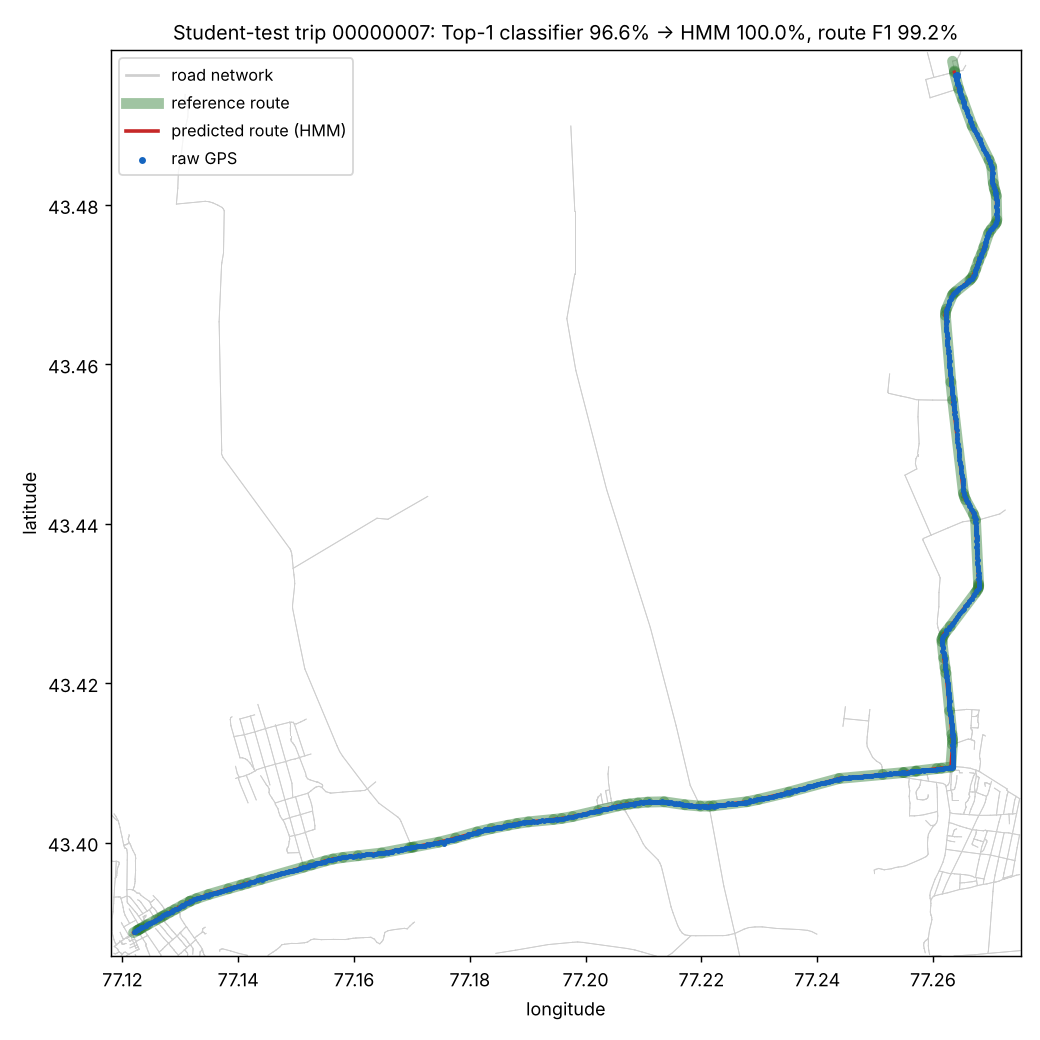

map_pred_trip_00000056.png


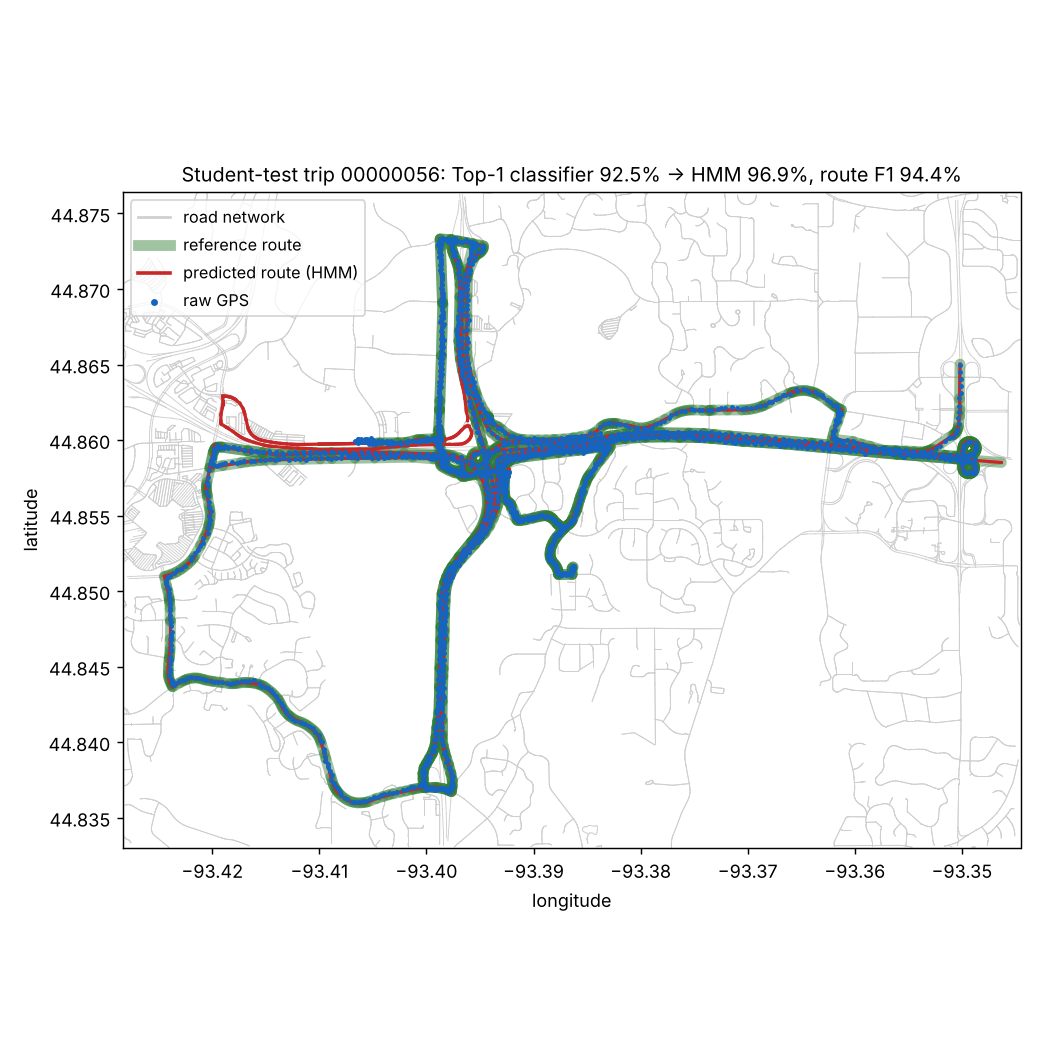

map_pred_trip_00000077.png


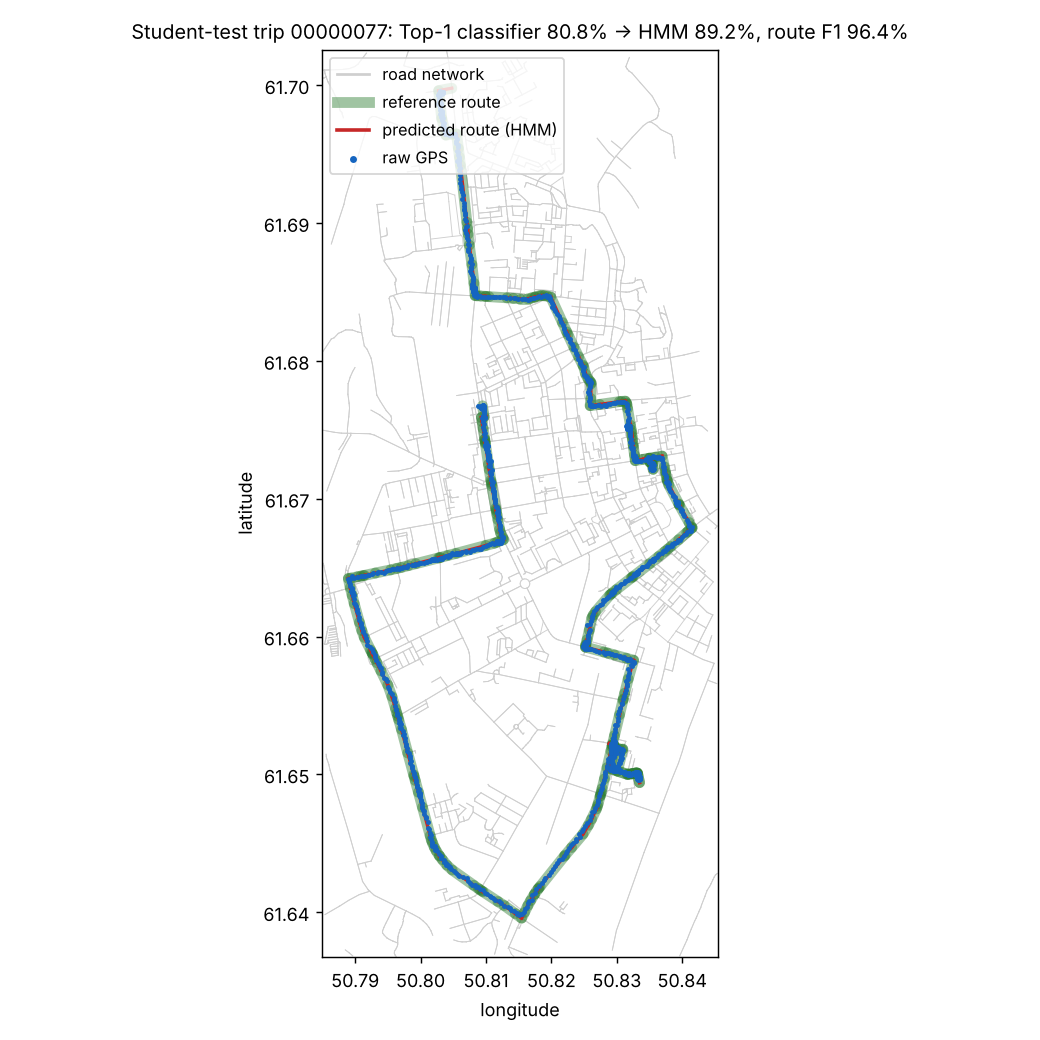

In [5]:
from IPython.display import Image, display
for f in sorted(C.FIGURES.glob("map_pred_trip_*.png")):
    print(f.name); display(Image(str(f), width=800))

Open the interactive maps in a browser: `maps/pred_trip_<id>.html`.